# 01 · EDA de la OBT: anticipar la mora en tarjetas de crédito

**Objetivo:** entender la OBT del PSet 2 (`PSET2_MORA.OBT.OBT_CUSTOMER_DEFAULT`, una fila por cliente al cierre de sep-2005, target = impago en oct-2005) y decidir qué cambia en el experimento.

> La exploración estadística se hace **solo sobre el conjunto de entrenamiento** (80 %). Así, ninguna decisión de modelado se toma mirando el hold-out.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from src.datos import cargar_obt, dividir, TARGET
from src.pipeline import MONTOS

pd.set_option('display.max_columns', 60); pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
IMG = '../docs/img/'

obt, meta = cargar_obt()          # lee Snowflake la primera vez y guarda data/obt.parquet
meta

{'tabla_origen': 'PSET2_MORA.OBT.OBT_CUSTOMER_DEFAULT',
 'fecha_corte_snapshot': '2005-09-30',
 'fecha_extraccion': '2026-11-18T22:22:34+00:00',
 'hash_dataset': '372bafd08cb627ae',
 'n_filas': 30000,
 'n_columnas': 53}

## 1. Tamaño, tipos y faltantes

In [2]:
print('OBT completa:', obt.shape)
X_train, X_test, y_train, y_test = dividir(obt)
train = X_train.assign(**{TARGET: y_train.values})
print('Entrenamiento:', train.shape, '| Prueba (no se mira):', X_test.shape)
resumen = pd.DataFrame({'tipo': obt.dtypes.astype(str), 'faltantes': obt.isna().sum(),
                        '%_faltantes': (obt.isna().mean()*100).round(2), 'unicos': obt.nunique()})
resumen

OBT completa: (30000, 53)
Entrenamiento: (24000, 44) | Prueba (no se mira): (6000, 43)


,tipo,faltantes,%_faltantes,unicos
customer_key,object,0,0.0,30000
customer_id,int64,0,0.0,30000
limit_bal,float64,0,0.0,81
education_code,float64,0,0.0,4
education,object,0,0.0,4
is_education_imputed,float64,0,0.0,2
is_marriage_imputed,float64,0,0.0,2
age,float64,0,0.0,56
age_band,object,0,0.0,5
is_inactive_6m,float64,0,0.0,2


In [3]:
import json
from src.datos import columnas_vacias
con_nulos = resumen[resumen.faltantes > 0]
vacias = columnas_vacias(obt)
print('Columnas con faltantes:', con_nulos['%_faltantes'].to_dict())
print('Columnas 100% vacías (se excluyen de las features):', vacias)
print('Tipos:', resumen.tipo.value_counts().to_dict())
json.dump({'faltantes_pct': con_nulos['%_faltantes'].to_dict(), 'vacias': vacias, 'hash': meta['hash_dataset']},
          open('../docs/eda_resumen.json', 'w'), ensure_ascii=False)

Columnas con faltantes: {'avg_payment_ratio_6m': 100.0}
Columnas 100% vacías (se excluyen de las features): ['avg_payment_ratio_6m']
Tipos: {'float64': 47, 'object': 4, 'int64': 2}


## 2. Estadística descriptiva

In [4]:
clave = [c for c in ['limit_bal','age','bill_amt_m1','pay_amt_m1','util_m1','pay_status_m1','max_delay_6m',
         'n_delinquent_months_6m','avg_utilization_6m','avg_payment_ratio_6m','total_pay_amt_6m'] if c not in vacias]
desc = train[clave].describe(percentiles=[.01,.25,.5,.75,.99]).T
desc['asimetria'] = train[clave].skew()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria
limit_bal,24000.0,167364.67,129511.31,10000.00,10000.00,50000.00,140000.00,240000.00,500000.00,1000000.00,1.00
age,24000.0,35.43,9.20,21.00,22.00,28.00,34.00,41.00,60.00,75.00,0.74
bill_amt_m1,24000.0,51100.50,73510.03,-165580.00,-77.01,3513.75,22330.00,66966.50,348402.41,964511.00,2.69
pay_amt_m1,24000.0,5623.56,16148.32,0.00,0.00,1000.00,2100.50,5018.25,67572.32,873552.00,15.31
util_m1,24000.0,0.42,0.41,-0.62,-0.00,0.02,0.31,0.83,1.23,6.46,0.81
pay_status_m1,24000.0,-0.01,1.12,-2.00,-2.00,-1.00,0.00,0.00,3.00,8.00,0.74
max_delay_6m,24000.0,0.68,1.07,0.00,0.00,0.00,0.00,2.00,4.00,8.00,1.68
n_delinquent_months_6m,24000.0,0.84,1.55,0.00,0.00,0.00,0.00,1.00,6.00,6.00,2.12
avg_utilization_6m,24000.0,0.37,0.35,-0.23,0.00,0.03,0.28,0.69,1.05,5.36,0.67
total_pay_amt_6m,24000.0,31509.49,59103.44,0.00,0.00,6700.00,14434.00,33856.25,268289.11,3764066.00,14.87


## 3. Distribución del target y desbalance

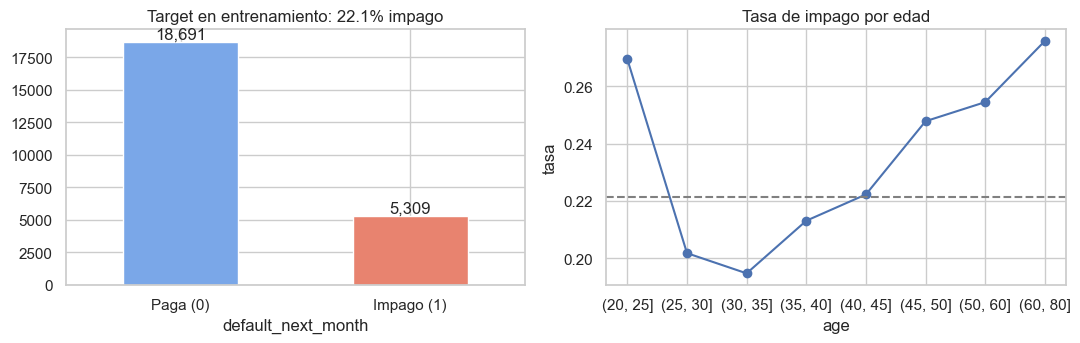

Desbalance: 22.12% positivos -> razón 3.5:1. Un clasificador "siempre paga" tendría 77.9% de accuracy.


In [5]:
tasa = y_train.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
y_train.value_counts().sort_index().plot.bar(ax=ax[0], color=['#7aa7e8', '#e8836f'])
ax[0].set_xticklabels(['Paga (0)', 'Impago (1)'], rotation=0); ax[0].set_title(f'Target en entrenamiento: {tasa:.1%} impago')
for p in ax[0].patches: ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
tasa_edad = train.groupby(pd.cut(train.age, [20,25,30,35,40,45,50,60,80]))[TARGET].mean()
tasa_edad.plot(ax=ax[1], marker='o'); ax[1].axhline(tasa, ls='--', c='gray'); ax[1].set_title('Tasa de impago por edad'); ax[1].set_ylabel('tasa')
plt.tight_layout(); plt.savefig(IMG+'eda_target.png', dpi=150); plt.show()
print(f'Desbalance: {tasa:.2%} positivos -> razón {(1-tasa)/tasa:.1f}:1. Un clasificador "siempre paga" tendría {(1-tasa):.1%} de accuracy.')

## 4. Valores atípicos: IQR (boxplots) y Z-score (|z| ≥ 3)

In [6]:
cols_out = [c for c in ['limit_bal','bill_amt_m1','pay_amt_m1','pay_amt_m2','total_pay_amt_6m','util_m1','age','avg_payment_ratio_6m'] if c not in vacias]
filas = []
for c in cols_out:
    s = train[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    out_iqr = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).mean()
    out_z = (np.abs(stats.zscore(s)) >= 3).mean()
    filas.append({'variable': c, '%_atipicos_IQR': round(out_iqr*100, 2), '%_atipicos_z>=3': round(out_z*100, 2),
                  'asimetria': round(s.skew(), 2), 'max': s.max(), 'p99': s.quantile(.99)})
atipicos = pd.DataFrame(filas).set_index('variable'); atipicos

,%_atipicos_IQR,%_atipicos_z>=3,asimetria,max,p99
variable,,,,,
limit_bal,0.57,0.45,1.00,1.000000e+06,500000.00000
bill_amt_m1,7.91,2.26,2.69,9.645110e+05,348402.41000
pay_amt_m1,9.04,1.37,15.31,8.735520e+05,67572.32000
pay_amt_m2,9.10,1.18,21.12,1.215471e+06,77010.79000
total_pay_amt_6m,9.46,1.78,14.87,3.764066e+06,268289.11000
util_m1,0.11,0.39,0.81,6.455300e+00,1.23352
age,0.89,0.46,0.74,7.500000e+01,60.00000


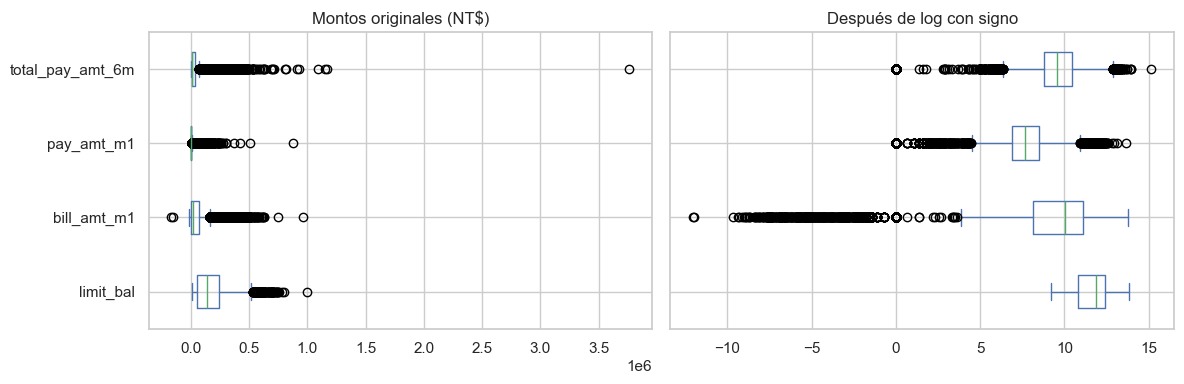

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m = ['limit_bal','bill_amt_m1','pay_amt_m1','total_pay_amt_6m']
train[m].plot.box(ax=ax[0], vert=False); ax[0].set_title('Montos originales (NT$)'); ax[0].ticklabel_format(axis='x', style='sci', scilimits=(0,0))
(np.sign(train[m])*np.log1p(np.abs(train[m]))).plot.box(ax=ax[1], vert=False); ax[1].set_title('Después de log con signo'); ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(IMG+'eda_outliers.png', dpi=150); plt.show()

In [8]:
# ¿Los atípicos son errores o clientes reales? Tasa de impago dentro y fuera del bloque atípico de pay_amt_m1
s = train.pay_amt_m1; q1, q3 = s.quantile([.25,.75]); lim = q3 + 1.5*(q3-q1)
print(f'pay_amt_m1 > {lim:,.0f}: tasa de impago {train.loc[s>lim, TARGET].mean():.1%} vs {train.loc[s<=lim, TARGET].mean():.1%} en el resto')

pay_amt_m1 > 11,046: tasa de impago 12.3% vs 23.1% en el resto


## 5. Relación target–features: Spearman

Uso **Spearman** y no Pearson por tres razones: (1) los montos son muy asimétricos y con atípicos (sección 4), y Pearson se deja dominar por ellos; (2) `pay_status_*` es **ordinal** (−2 < −1 < 0 < 1 …), no de intervalo; (3) el target es binario, y Spearman mide asociación **monótona** sin suponer linealidad.

In [9]:
num = train.select_dtypes('number').drop(columns=[TARGET] + [c for c in vacias if c in train])
rho = num.apply(lambda c: stats.spearmanr(c, train[TARGET], nan_policy='omit')[0]).sort_values(key=np.abs, ascending=False)
pear = num.apply(lambda c: c.corr(train[TARGET])).reindex(rho.index)
corr_t = pd.DataFrame({'spearman': rho.round(3), 'pearson': pear.round(3)})
corr_t.head(15)

,spearman,pearson
n_delinquent_months_3m,0.393,0.400
n_delinquent_months_6m,0.393,0.401
max_delay_6m,0.378,0.374
is_delinquent_last_month,0.371,0.371
pay_status_m1,0.297,0.328
pay_status_m2,0.219,0.266
pay_status_m3,0.199,0.239
pay_status_m4,0.179,0.220
limit_bal,-0.178,-0.161
total_pay_amt_6m,-0.173,-0.102


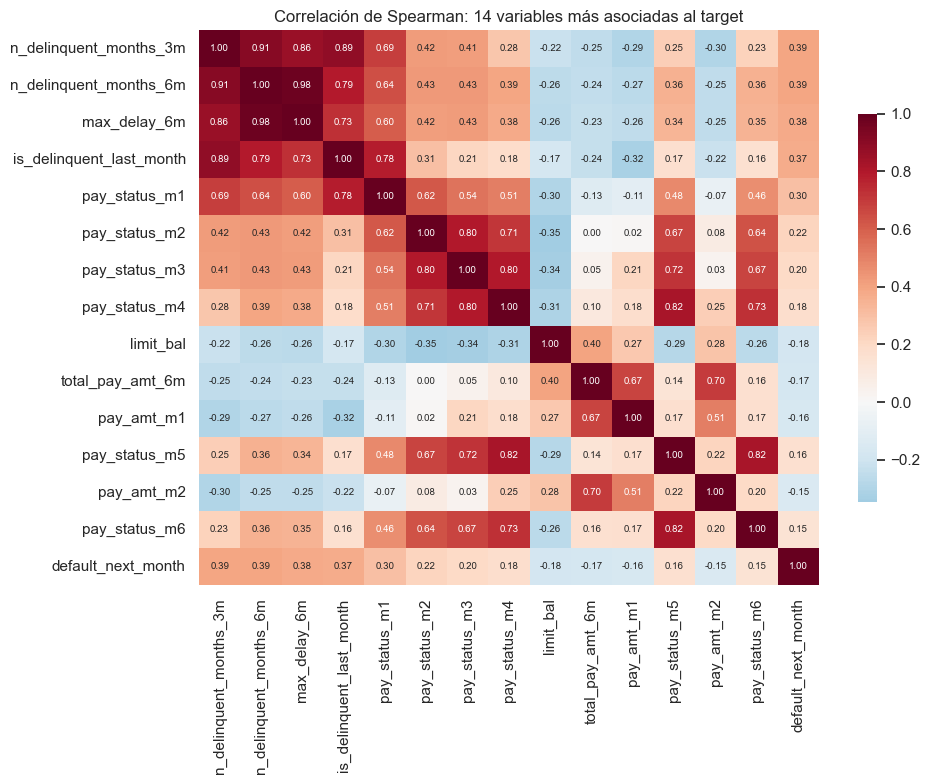

In [10]:
top = list(rho.index[:14]) + [TARGET]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(train[top].corr(method='spearman'), cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size':7}, ax=ax, cbar_kws={'shrink':.7})
ax.set_title('Correlación de Spearman: 14 variables más asociadas al target')
plt.tight_layout(); plt.savefig(IMG+'eda_heatmap.png', dpi=150); plt.show()

In [11]:
bills = [f'bill_amt_m{m}' for m in range(1,7)]
cb = train[bills].corr(method='spearman'); print('Spearman mínima entre bill_amt_m1..m6:', round(cb.values[np.triu_indices(6,1)].min(), 3))

Spearman mínima entre bill_amt_m1..m6: 0.732


## 6. Estado de pago del último mes: ¿la relación es monótona?

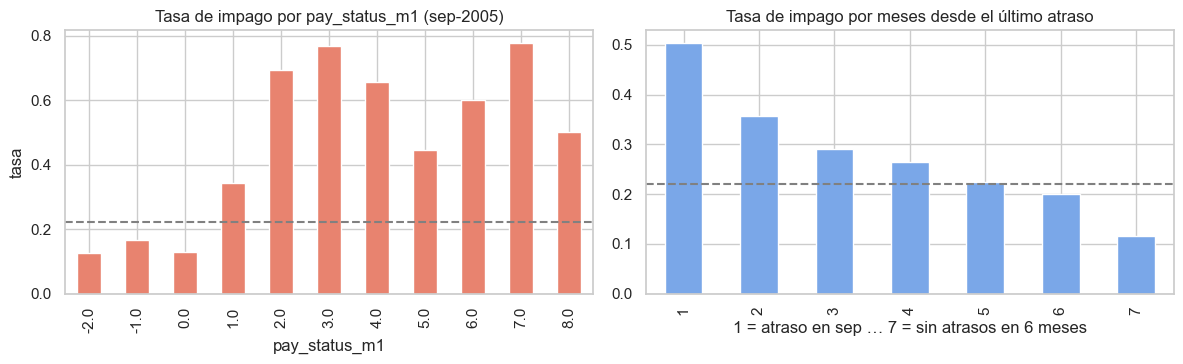

,tasa_impago,n,pct_clientes
pay_status_m1,,,
-2.0,0.126934,2198,9.2
-1.0,0.166335,4527,18.9
0.0,0.128003,11781,49.1
1.0,0.343667,3000,12.5
2.0,0.693639,2138,8.9
3.0,0.767347,245,1.0
4.0,0.655172,58,0.2
5.0,0.444444,18,0.1
6.0,0.600000,10,0.0


In [12]:
g = train.groupby('pay_status_m1')[TARGET].agg(['mean','size']).rename(columns={'mean':'tasa_impago','size':'n'})
g['pct_clientes'] = (g.n/len(train)*100).round(1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
g.tasa_impago.plot.bar(ax=ax[0], color='#e8836f'); ax[0].axhline(tasa, ls='--', c='gray'); ax[0].set_title('Tasa de impago por pay_status_m1 (sep-2005)'); ax[0].set_ylabel('tasa')
rec = np.where((train[[f'pay_status_m{m}' for m in range(1,7)]]>=1).any(axis=1), (train[[f'pay_status_m{m}' for m in range(1,7)]].values>=1).argmax(axis=1)+1, 7)
train.groupby(rec)[TARGET].mean().plot.bar(ax=ax[1], color='#7aa7e8'); ax[1].axhline(tasa, ls='--', c='gray')
ax[1].set_title('Tasa de impago por meses desde el último atraso'); ax[1].set_xlabel('1 = atraso en sep … 7 = sin atrasos en 6 meses')
plt.tight_layout(); plt.savefig(IMG+'eda_estado_pago.png', dpi=150); plt.show()
g

## 7. Hallazgos que afectan el modelado

In [13]:
g_ = g.tasa_impago
hallazgos = pd.DataFrame([
 {'Hallazgo': 'H1. Clases desbalanceadas',
  'Evidencia': f'{tasa:.1%} de impagos (razón {(1-tasa)/tasa:.1f}:1); "siempre paga" tendría {(1-tasa):.1%} de accuracy',
  'Consecuencia en el modelo': 'CV estratificada; AUC-ROC y AP en vez de accuracy; umbral elegido por costo, no 0,5'},
 {'Hallazgo': 'H2. Montos con cola larga y atípicos legítimos',
  'Evidencia': f"pay_amt_m1: {atipicos.loc['pay_amt_m1','%_atipicos_IQR']}% atípicos IQR, asimetría {atipicos.loc['pay_amt_m1','asimetria']}; los atípicos tienen menos impago ({train.loc[s>lim, TARGET].mean():.1%})",
  'Consecuencia en el modelo': 'No eliminarlos (son clientes reales e informativos); log con signo en los montos para modelos lineales y redes'},
 {'Hallazgo': 'H3. El atraso reciente domina la señal',
  'Evidencia': f"Spearman: pay_status_m1 = {rho['pay_status_m1']:.2f}, max_delay_6m = {rho['max_delay_6m']:.2f}; impago {train.groupby(rec)[TARGET].mean().iloc[0]:.0%} si el atraso fue en sep vs {train.groupby(rec)[TARGET].mean().iloc[-1]:.0%} sin atrasos",
  'Consecuencia en el modelo': 'Feature de recencia meses_desde_ultimo_atraso; la regla de negocio (atraso en sep) es una baseline fuerte que hay que superar'},
 {'Hallazgo': 'H4. Relación no monótona en estados −2/−1/0',
  'Evidencia': f"impago {g_.get(-2,np.nan):.1%} (−2), {g_.get(-1,np.nan):.1%} (−1), {g_.get(0,np.nan):.1%} (0): «pago total» (−1) es más riesgoso que «pago mínimo» (0); el orden numérico no refleja el riesgo",
  'Consecuencia en el modelo': 'estado_ultimo_mes como categórica con one-hot (no como número)'},
 {'Hallazgo': 'H5. Colinealidad entre saldos mensuales',
  'Evidencia': f'Spearman mínima entre bill_amt_m1..m6 = {cb.values[np.triu_indices(6,1)].min():.2f}',
  'Consecuencia en el modelo': 'Regularización L2 en el lineal; se agregan tendencias (tendencia_utilizacion) en vez de más niveles'},
])
if vacias:
    hallazgos = pd.concat([hallazgos, pd.DataFrame([{
        'Hallazgo': 'H6. Columna vacía desde la OBT',
        'Evidencia': f"{', '.join(vacias)}: 100% nula en Snowflake (en el pipeline local del PSet 2 tenía datos: se perdió al escribir la OBT)",
        'Consecuencia en el modelo': 'Se excluye de las features (src/datos.columnas_vacias); se reporta como defecto a corregir en el PSet 2'}])], ignore_index=True)
pd.set_option('display.max_colwidth', 200)
hallazgos.to_csv('../docs/hallazgos_eda.csv', index=False)
hallazgos

,Hallazgo,Evidencia,Consecuencia en el modelo
0,H1. Clases desbalanceadas,"22.1% de impagos (razón 3.5:1); ""siempre paga"" tendría 77.9% de accuracy","CV estratificada; AUC-ROC y AP en vez de accuracy; umbral elegido por costo, no 0,5"
1,H2. Montos con cola larga y atípicos legítimos,"pay_amt_m1: 9.04% atípicos IQR, asimetría 15.31; los atípicos tienen menos impago (12.3%)",No eliminarlos (son clientes reales e informativos); log con signo en los montos para modelos lineales y redes
2,H3. El atraso reciente domina la señal,"Spearman: pay_status_m1 = 0.30, max_delay_6m = 0.38; impago 50% si el atraso fue en sep vs 12% sin atrasos",Feature de recencia meses_desde_ultimo_atraso; la regla de negocio (atraso en sep) es una baseline fuerte que hay que superar
3,H4. Relación no monótona en estados −2/−1/0,"impago 12.7% (−2), 16.6% (−1), 12.8% (0): «pago total» (−1) es más riesgoso que «pago mínimo» (0); el orden numérico no refleja el riesgo",estado_ultimo_mes como categórica con one-hot (no como número)
4,H5. Colinealidad entre saldos mensuales,Spearman mínima entre bill_amt_m1..m6 = 0.73,Regularización L2 en el lineal; se agregan tendencias (tendencia_utilizacion) en vez de más niveles
5,H6. Columna vacía desde la OBT,avg_payment_ratio_6m: 100% nula en Snowflake (en el pipeline local del PSet 2 tenía datos: se perdió al escribir la OBT),Se excluye de las features (src/datos.columnas_vacias); se reporta como defecto a corregir en el PSet 2
